In [1]:
import sys
import pandas as pd
import numpy as np
import sklearn
import xgboost as xgb
import lightgbm as lgb
import shap

print("Ruta del entorno Python:", sys.executable)
print(f"Pandas: {pd.__version__} | Scikit-Learn: {sklearn.__version__} | XGBoost: {xgb.__version__}")

# Cargar el dataset para verificar lectura
df = pd.read_csv('Telco-Customer-Churn.csv') # O 'Telco-Customer-Churn.csv' si lo renombraste
print(f"Dataset cargado con éxito: {df.shape[0]} filas y {df.shape[1]} columnas.")
df.head(3)

Ruta del entorno Python: c:\DiplomaturaCD\TP_Final_Churn_UTN\.venv\Scripts\python.exe
Pandas: 3.1.0 | Scikit-Learn: 1.9.1 | XGBoost: 3.4.1
Dataset cargado con éxito: 7043 filas y 21 columnas.


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


# Proyecto Final Integrador: Predicción del Abandono de Clientes (Churn) en Telecomunicaciones
**Diplomatura en Ciencia de Datos y Análisis Avanzado - UTN.BA**

### Metodología CRISP-DM y Enfoque de Negocio
* **Problema de Negocio:** Identificar de manera anticipada a los clientes con mayor probabilidad de abandonar el servicio (*churn*) para que las áreas de Retención, CRM y Marketing prioricen sus recursos de contacto.
* **Ajuste Metodológico (Entrega Final):** Un modelo predictivo estima probabilidades de baja y permite **priorizar acciones**, pero no reduce la tasa de churn por sí solo (lo cual requiere ejecutar una campaña comercial y medir su efecto incremental mediante pruebas A/B). Dado que el dataset no incluye resultados post-campaña, el **KPI operativo del modelo** se define como la **Capacidad de Concentración de Abandonos en el Top 20% de Mayor Riesgo (Recall @ Top 20% y Precision @ Top 20%)**, respondiendo a la pregunta de negocio: *"Si Retención puede contactar al 20% de la cartera, ¿cuántos abandonos reales logra concentrar allí?"*

In [2]:
# ==============================================================================
# FASE 2 CRISP-DM: AUDITORÍA DE CALIDAD DE DATOS Y LIMPIEZA
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Control de filas duplicadas y customerID repetidos
dup_rows = df.duplicated().sum()
dup_ids = df['customerID'].duplicated().sum()

# 2. Revisión de TotalCharges (espacios en blanco en clientes con antigüedad 0)
tc_numeric = pd.to_numeric(df['TotalCharges'], errors='coerce')
nulos_tc = tc_numeric.isna().sum()
tenure_nulos = df.loc[tc_numeric.isna(), 'tenure'].unique()

print(f"1. Duplicados -> Filas: {dup_rows} | customerID: {dup_ids}")
print(f"2. TotalCharges vacíos: {nulos_tc} casos ({nulos_tc/len(df)*100:.2f}%), todos con tenure = {tenure_nulos}")

# Aplicación de limpieza definida en Pre-entrega
df_clean = df.copy()
df_clean['TotalCharges'] = tc_numeric.fillna(0.0)
df_clean['Churn_bin'] = (df_clean['Churn'] == 'Yes').astype(int)

# 3. Control de Outliers mediante criterio IQR (1.5 * IQR) en las 3 variables numéricas clave
num_cols_base = ['tenure', 'MonthlyCharges', 'TotalCharges']
resumen_calidad = []

for col in num_cols_base:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    outliers = ((df_clean[col] < (q1 - 1.5 * iqr)) | (df_clean[col] > (q3 + 1.5 * iqr))).sum()
    resumen_calidad.append({
        'Variable': col,
        'Media': round(df_clean[col].mean(), 2),
        'Mediana': round(df_clean[col].median(), 2),
        'Desv_Std': round(df_clean[col].std(), 2),
        'Min': df_clean[col].min(),
        'Max': df_clean[col].max(),
        'Outliers_IQR': outliers
    })

print("\n3. Resumen Estadístico y Control de Outliers IQR:")
display(pd.DataFrame(resumen_calidad))

1. Duplicados -> Filas: 0 | customerID: 0
2. TotalCharges vacíos: 11 casos (0.16%), todos con tenure = [0]

3. Resumen Estadístico y Control de Outliers IQR:


,Variable,Media,Mediana,Desv_Std,Min,Max,Outliers_IQR
0,tenure,32.37,29.00,24.56,0.00,72.00,0
1,MonthlyCharges,64.76,70.35,30.09,18.25,118.75,0
2,TotalCharges,2279.73,1394.55,2266.79,0.00,8684.80,0


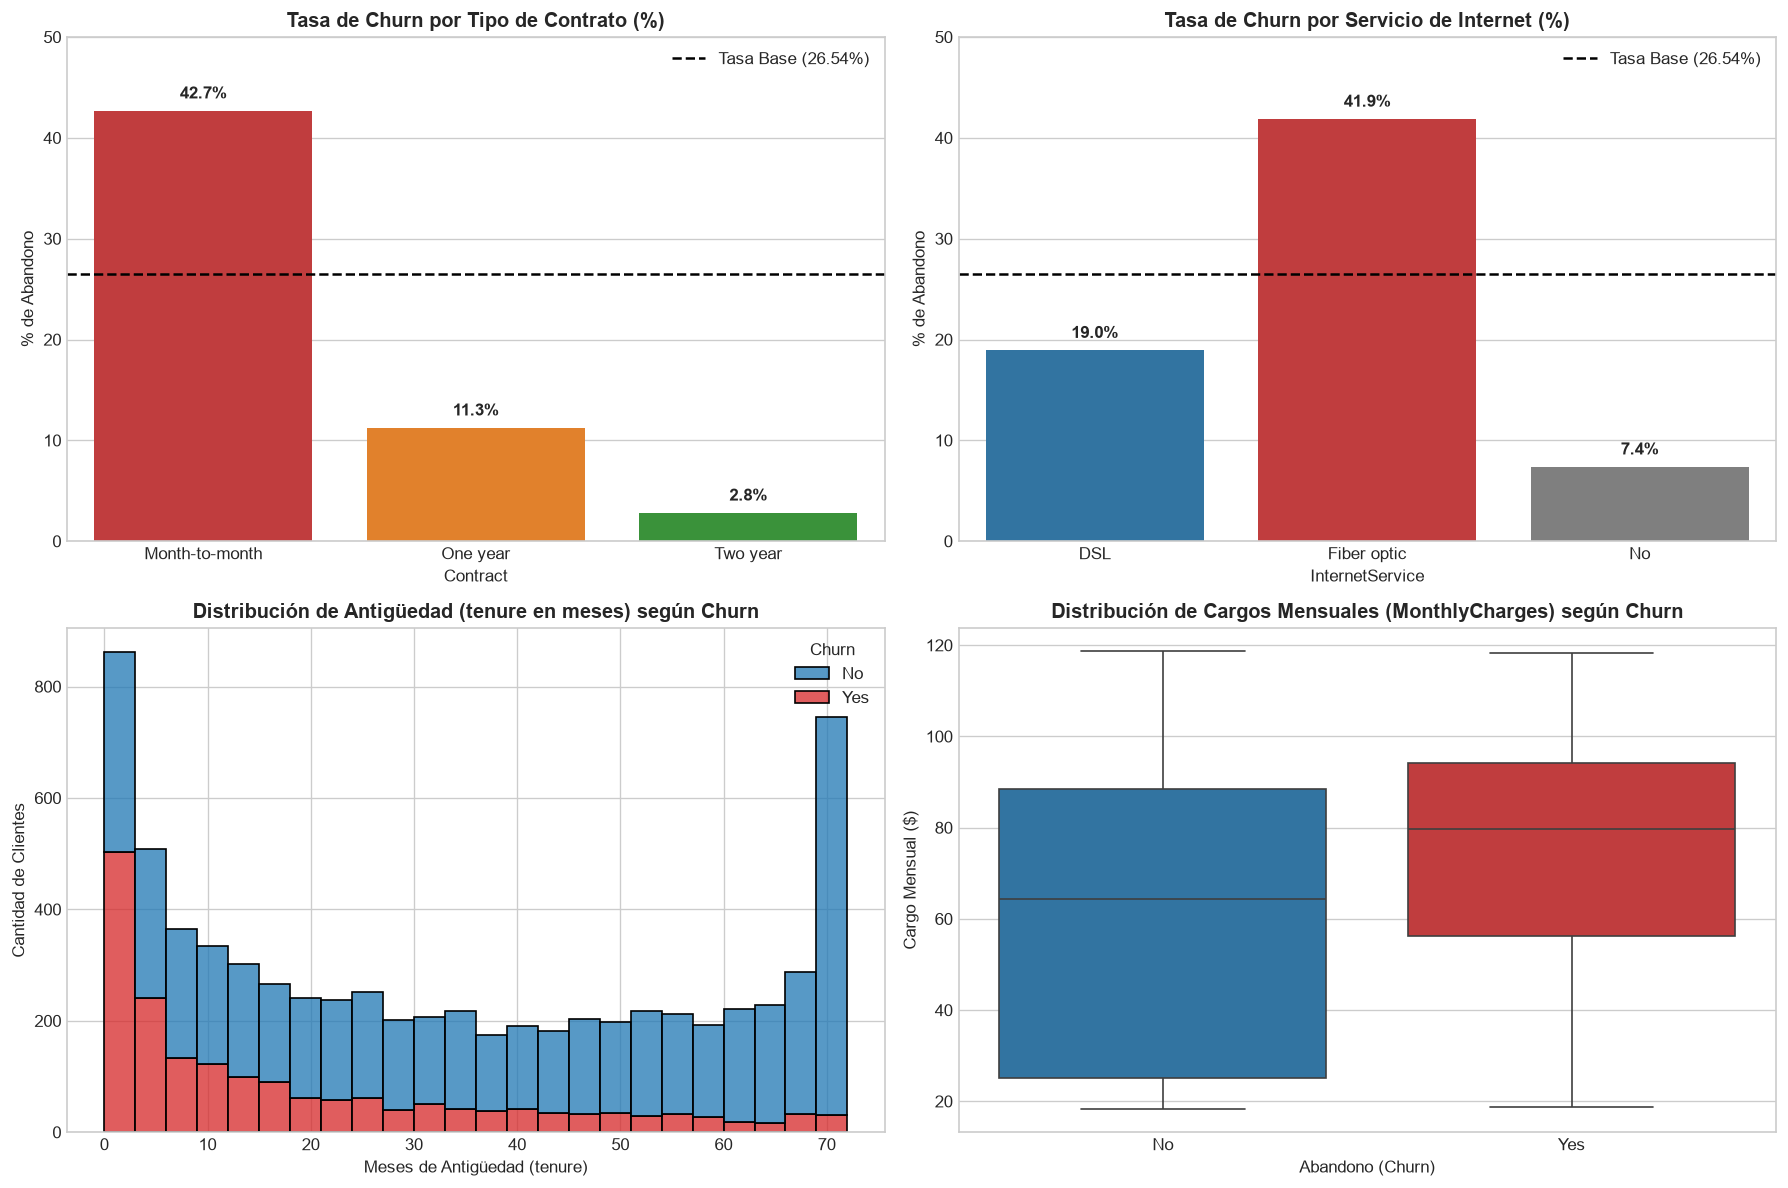

In [3]:
# ==============================================================================
# ANÁLISIS EXPLORATORIO DE DATOS (EDA) - FACTORES CLAVE DE ABANDONO
# ==============================================================================
plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(2, 2, figsize=(15, 10), dpi=120)
tasa_base = df_clean['Churn_bin'].mean() * 100

# 1. Churn por Tipo de Contrato
ax1 = axes[0, 0]
contract_churn = df_clean.groupby('Contract')['Churn_bin'].mean().mul(100).reset_index()
sns.barplot(data=contract_churn, x='Contract', y='Churn_bin', hue='Contract',
            palette=['#d62728', '#ff7f0e', '#2ca02c'], ax=ax1, legend=False)
ax1.axhline(tasa_base, color='black', linestyle='--', label=f'Tasa Base ({tasa_base:.2f}%)')
for i, v in enumerate(contract_churn['Churn_bin']):
    ax1.text(i, v + 1.2, f"{v:.1f}%", ha='center', fontweight='bold')
ax1.set_title('Tasa de Churn por Tipo de Contrato (%)', fontweight='bold')
ax1.set_ylim(0, 50)
ax1.set_ylabel('% de Abandono')
ax1.legend()

# 2. Churn por Servicio de Internet
ax2 = axes[0, 1]
internet_churn = df_clean.groupby('InternetService')['Churn_bin'].mean().mul(100).reset_index()
sns.barplot(data=internet_churn, x='InternetService', y='Churn_bin', hue='InternetService',
            palette=['#1f77b4', '#d62728', '#7f7f7f'], ax=ax2, legend=False)
ax2.axhline(tasa_base, color='black', linestyle='--', label=f'Tasa Base ({tasa_base:.2f}%)')
for i, v in enumerate(internet_churn['Churn_bin']):
    ax2.text(i, v + 1.2, f"{v:.1f}%", ha='center', fontweight='bold')
ax2.set_title('Tasa de Churn por Servicio de Internet (%)', fontweight='bold')
ax2.set_ylim(0, 50)
ax2.set_ylabel('% de Abandono')
ax2.legend()

# 3. Distribución de Antigüedad (tenure) según Churn
ax3 = axes[1, 0]
sns.histplot(data=df_clean, x='tenure', hue='Churn', multiple='stack',
             palette={'No': '#1f77b4', 'Yes': '#d62728'}, bins=24, ax=ax3)
ax3.set_title('Distribución de Antigüedad (tenure en meses) según Churn', fontweight='bold')
ax3.set_xlabel('Meses de Antigüedad (tenure)')
ax3.set_ylabel('Cantidad de Clientes')

# 4. Cargos Mensuales (MonthlyCharges) según Churn
ax4 = axes[1, 1]
sns.boxplot(data=df_clean, x='Churn', y='MonthlyCharges', hue='Churn',
            palette={'No': '#1f77b4', 'Yes': '#d62728'}, ax=ax4, legend=False)
ax4.set_title('Distribución de Cargos Mensuales (MonthlyCharges) según Churn', fontweight='bold')
ax4.set_xlabel('Abandono (Churn)')
ax4.set_ylabel('Cargo Mensual ($)')

plt.tight_layout()
plt.show()

In [4]:
# ==============================================================================
# FASE 3 CRISP-DM: INGENIERÍA DE VARIABLES (FEATURE ENGINEERING)
# ==============================================================================
df_fe = df_clean.copy()

# 1. Cantidad total de servicios adicionales contratados (0 a 6)
servicios_extra = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 
                   'TechSupport', 'StreamingTV', 'StreamingMovies']
df_fe['cant_servicios_adicionales'] = (df_fe[servicios_extra] == 'Yes').sum(axis=1)

# 2. Indicador de cliente de internet "Sin Blindaje Técnico" (sin seguridad online ni soporte técnico)
df_fe['sin_blindaje_tecnico'] = (
    (df_fe['InternetService'] != 'No') & 
    (df_fe['OnlineSecurity'] == 'No') & 
    (df_fe['TechSupport'] == 'No')
).astype(int)

# 3. Presión tarifaria temprana (Cargo mensual relativo a los meses de antigüedad)
df_fe['ratio_cargo_antiguedad'] = df_fe['MonthlyCharges'] / (df_fe['tenure'] + 1)

print("Comparativa de las nuevas variables según Churn (Promedio):")
display(df_fe.groupby('Churn')[['cant_servicios_adicionales', 'sin_blindaje_tecnico', 'ratio_cargo_antiguedad']].mean().round(2))

Comparativa de las nuevas variables según Churn (Promedio):


,cant_servicios_adicionales,sin_blindaje_tecnico,ratio_cargo_antiguedad
Churn,,,
No,2.14,0.25,3.61
Yes,1.77,0.67,11.75


In [5]:
# ==============================================================================
# FASE 4 CRISP-DM: MODELADO Y EVALUACIÓN (TRAZABILIDAD PRE-ENTREGA + ENTREGA FINAL)
# ==============================================================================
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, recall_score, precision_score, f1_score,
    roc_auc_score, average_precision_score, precision_recall_curve, confusion_matrix
)
import xgboost as xgb

# 1. Definición de conjuntos Base (Pre-entrega) y con Feature Engineering (Entrega Final)
X_base = df_clean.drop(columns=['customerID', 'Churn', 'Churn_bin'])
X_fe = df_fe.drop(columns=['customerID', 'Churn', 'Churn_bin'])
y = df_clean['Churn_bin']

# Partición Holdout Estratificada 80/20 (random_state=42)
X_train_b, X_test_b, y_train, y_test = train_test_split(X_base, y, test_size=0.20, stratify=y, random_state=42)
X_train_fe, X_test_fe, _, _ = train_test_split(X_fe, y, test_size=0.20, stratify=y, random_state=42)

# Preprocesadores
num_cols_b = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_cols_b = [c for c in X_base.columns if c not in num_cols_b]
prep_base = ColumnTransformer([
    ('num', StandardScaler(), num_cols_b),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols_b)
])

num_cols_fe = ['tenure', 'MonthlyCharges', 'TotalCharges', 
               'cant_servicios_adicionales', 'sin_blindaje_tecnico', 'ratio_cargo_antiguedad']
cat_cols_fe = [c for c in X_fe.columns if c not in num_cols_fe]
prep_fe = ColumnTransformer([
    ('num', StandardScaler(), num_cols_fe),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols_fe)
])

# Peso para balancear clase positiva en XGBoost
scale_pos = (y_train == 0).sum() / (y_train == 1).sum()

# Configuración de experimentos: (Nombre, Clasificador, usa_FE)
experimentos = [
    ('1. Baseline (Dummy Mayoritaria)', DummyClassifier(strategy='most_frequent', random_state=42), False),
    ('2. Reg. Logística Estándar (Pre-entrega)', LogisticRegression(max_iter=1000, random_state=42), False),
    ('3. Reg. Logística Balanceada (Pre-entrega)', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42), False),
    ('4. Árbol de Decisión (max_depth=5, Bal.)', DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42), True),
    ('5. Random Forest Balanceado (con FE)', RandomForestClassifier(n_estimators=200, max_depth=8, class_weight='balanced', random_state=42), True),
    ('6. XGBoost Balanceado (con FE)', xgb.XGBClassifier(n_estimators=100, max_depth=4, learning_rate=0.05, scale_pos_weight=scale_pos, eval_metric='logloss', random_state=42), True)
]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
k_top20 = int(round(len(y_test) * 0.20))  # 282 clientes (20% de 1.409 en Holdout)
total_churn_test = y_test.sum()           # 374 abandonos reales en Holdout
base_rate_test = y_test.mean()            # 26,54%

resultados = []
probs_test = {}
modelos_entrenados = {}

for nombre, clf, usa_fe in experimentos:
    X_tr = X_train_fe if usa_fe else X_train_b
    X_te = X_test_fe if usa_fe else X_test_b
    prep = prep_fe if usa_fe else prep_base
    
    pipe = Pipeline([('prep', prep), ('clf', clf)])
    
    # Validación Cruzada 5-Fold sobre Train
    cv_res = cross_validate(
        pipe, X_tr, y_train, cv=cv,
        scoring=['recall', 'precision', 'roc_auc', 'average_precision'],
        n_jobs=-1
    )
    
    # Entrenamiento y evaluación en Holdout
    pipe.fit(X_tr, y_train)
    modelos_entrenados[nombre] = pipe
    y_pred = pipe.predict(X_te)
    y_prob = pipe.predict_proba(X_te)[:, 1]
    probs_test[nombre] = y_prob
    
    # Evaluación en el Top 20% de mayor riesgo (Capacidad operativa de Retención)
    if 'Baseline' in nombre:
        bajas_top20 = int(round(k_top20 * base_rate_test))
        prec_top20 = base_rate_test
        rec_top20 = bajas_top20 / total_churn_test
        lift_top20 = 1.0
    else:
        top_idx = np.argsort(y_prob)[::-1][:k_top20]
        bajas_top20 = int(y_test.iloc[top_idx].sum())
        prec_top20 = y_test.iloc[top_idx].mean()
        rec_top20 = bajas_top20 / total_churn_test
        lift_top20 = prec_top20 / base_rate_test
        
    resultados.append({
        'Modelo': nombre,
        'CV Recall': round(cv_res['test_recall'].mean(), 3),
        'CV ROC-AUC': round(cv_res['test_roc_auc'].mean(), 3),
        'Holdout Recall': round(recall_score(y_test, y_pred, zero_division=0), 3),
        'Holdout Precision': round(precision_score(y_test, y_pred, zero_division=0), 3),
        'Holdout F1': round(f1_score(y_test, y_pred, zero_division=0), 3),
        'Holdout ROC-AUC': round(roc_auc_score(y_test, y_prob), 3),
        'Holdout PR-AUC': round(average_precision_score(y_test, y_prob), 3),
        'Bajas en Top 20% (de 282)': bajas_top20,
        'Precision @ Top 20% (%)': round(prec_top20 * 100, 2),
        'Recall @ Top 20% (% Concentrado)': round(rec_top20 * 100, 2),
        'Lift @ Top 20%': round(lift_top20, 2)
    })

df_resultados = pd.DataFrame(resultados)
display(df_resultados)

,Modelo,CV Recall,CV ROC-AUC,Holdout Recall,Holdout Precision,Holdout F1,Holdout ROC-AUC,Holdout PR-AUC,Bajas en Top 20% (de 282),Precision @ Top 20% (%),Recall @ Top 20% (% Concentrado),Lift @ Top 20%
0,1. Baseline (Dummy Mayoritaria),0.000,0.500,0.000,0.000,0.000,0.500,0.265,75,26.54,20.05,1.00
1,2. Reg. Logística Estándar (Pre-entrega),0.544,0.846,0.559,0.657,0.604,0.842,0.634,186,65.96,49.73,2.48
2,3. Reg. Logística Balanceada (Pre-entrega),0.801,0.846,0.783,0.504,0.614,0.842,0.633,186,65.96,49.73,2.48
3,"4. Árbol de Decisión (max_depth=5, Bal.)",0.786,0.826,0.770,0.531,0.629,0.835,0.619,186,65.96,49.73,2.48
4,5. Random Forest Balanceado (con FE),0.777,0.848,0.805,0.535,0.642,0.844,0.659,192,68.09,51.34,2.57
5,6. XGBoost Balanceado (con FE),0.790,0.849,0.797,0.518,0.628,0.845,0.653,188,66.67,50.27,2.51


In [6]:
# ==============================================================================
# FASE 5 CRISP-DM: TRADUCCIÓN DE VALOR DE NEGOCIO (TABLA POR QUINTILES EN HOLDOUT)
# ==============================================================================
# Utilizamos las probabilidades del modelo de Regresión Logística (65,96% en Top 20%)
y_prob_elegido = probs_test['3. Reg. Logística Balanceada (Pre-entrega)']

df_ranking = pd.DataFrame({
    'Churn_Real': y_test.values,
    'Prob_Churn': y_prob_elegido
}).sort_values(by='Prob_Churn', ascending=False).reset_index(drop=True)

# Dividimos la cartera de Holdout (1.409 clientes) en 5 tramos iguales del 20% (Quintiles)
df_ranking['Tramo_Cartera'] = pd.qcut(df_ranking.index, q=5, labels=[
    'Quintil 1 (Top 0% - 20% Mayor Riesgo)',
    'Quintil 2 (20% - 40% Riesgo Medio-Alto)',
    'Quintil 3 (40% - 60% Riesgo Medio)',
    'Quintil 4 (60% - 80% Riesgo Bajo)',
    'Quintil 5 (80% - 100% Menor Riesgo)'
])

tabla_quintiles = df_ranking.groupby('Tramo_Cartera', observed=False).agg(
    Clientes_Contactados=('Churn_Real', 'count'),
    Abandonos_Reales_En_Tramo=('Churn_Real', 'sum'),
    Tasa_Churn_Tramo_Pct=('Churn_Real', lambda x: round(x.mean() * 100, 2))
).reset_index()

tabla_quintiles['Clientes_Acumulados'] = tabla_quintiles['Clientes_Contactados'].cumsum()
tabla_quintiles['Abandonos_Concentrados_Acum'] = tabla_quintiles['Abandonos_Reales_En_Tramo'].cumsum()
tabla_quintiles['Pct_Total_Abandonos_Concentrado (Recall Acum)'] = (
    tabla_quintiles['Abandonos_Concentrados_Acum'] / total_churn_test * 100
).round(2)
tabla_quintiles['Lift_Tramo'] = (
    (tabla_quintiles['Tasa_Churn_Tramo_Pct'] / 100) / base_rate_test
).round(2)

print("=== RESPUESTA PARA EL ÁREA DE RETENCIÓN (SOBRE 1.409 CLIENTES Y 374 BAJAS REALES EN TEST) ===")
print(f"-> Si Retención contacta al 20% de mayor riesgo ({tabla_quintiles.loc[0, 'Clientes_Contactados']} clientes):")
print(f"   * Acierta en el {tabla_quintiles.loc[0, 'Tasa_Churn_Tramo_Pct']}% de los casos (vs 26,54% al azar, Lift = {tabla_quintiles.loc[0, 'Lift_Tramo']}x).")
print(f"   * Logra concentrar {tabla_quintiles.loc[0, 'Abandonos_Reales_En_Tramo']} de los {total_churn_test} abandonos totales ({tabla_quintiles.loc[0, 'Pct_Total_Abandonos_Concentrado (Recall Acum)']}% de todas las bajas).\n")

display(tabla_quintiles)

=== RESPUESTA PARA EL ÁREA DE RETENCIÓN (SOBRE 1.409 CLIENTES Y 374 BAJAS REALES EN TEST) ===
-> Si Retención contacta al 20% de mayor riesgo (282 clientes):
   * Acierta en el 65.96% de los casos (vs 26,54% al azar, Lift = 2.48x).
   * Logra concentrar 186 de los 374 abandonos totales (49.73% de todas las bajas).



,Tramo_Cartera,Clientes_Contactados,Abandonos_Reales_En_Tramo,Tasa_Churn_Tramo_Pct,Clientes_Acumulados,Abandonos_Concentrados_Acum,Pct_Total_Abandonos_Concentrado (Recall Acum),Lift_Tramo
0,Quintil 1 (Top 0% - 20% Mayor Riesgo),282,186,65.96,282,186,49.73,2.48
1,Quintil 2 (20% - 40% Riesgo Medio-Alto),282,105,37.23,564,291,77.81,1.40
2,Quintil 3 (40% - 60% Riesgo Medio),281,59,21.00,845,350,93.58,0.79
3,Quintil 4 (60% - 80% Riesgo Bajo),282,21,7.45,1127,371,99.20,0.28
4,Quintil 5 (80% - 100% Menor Riesgo),282,3,1.06,1409,374,100.00,0.04


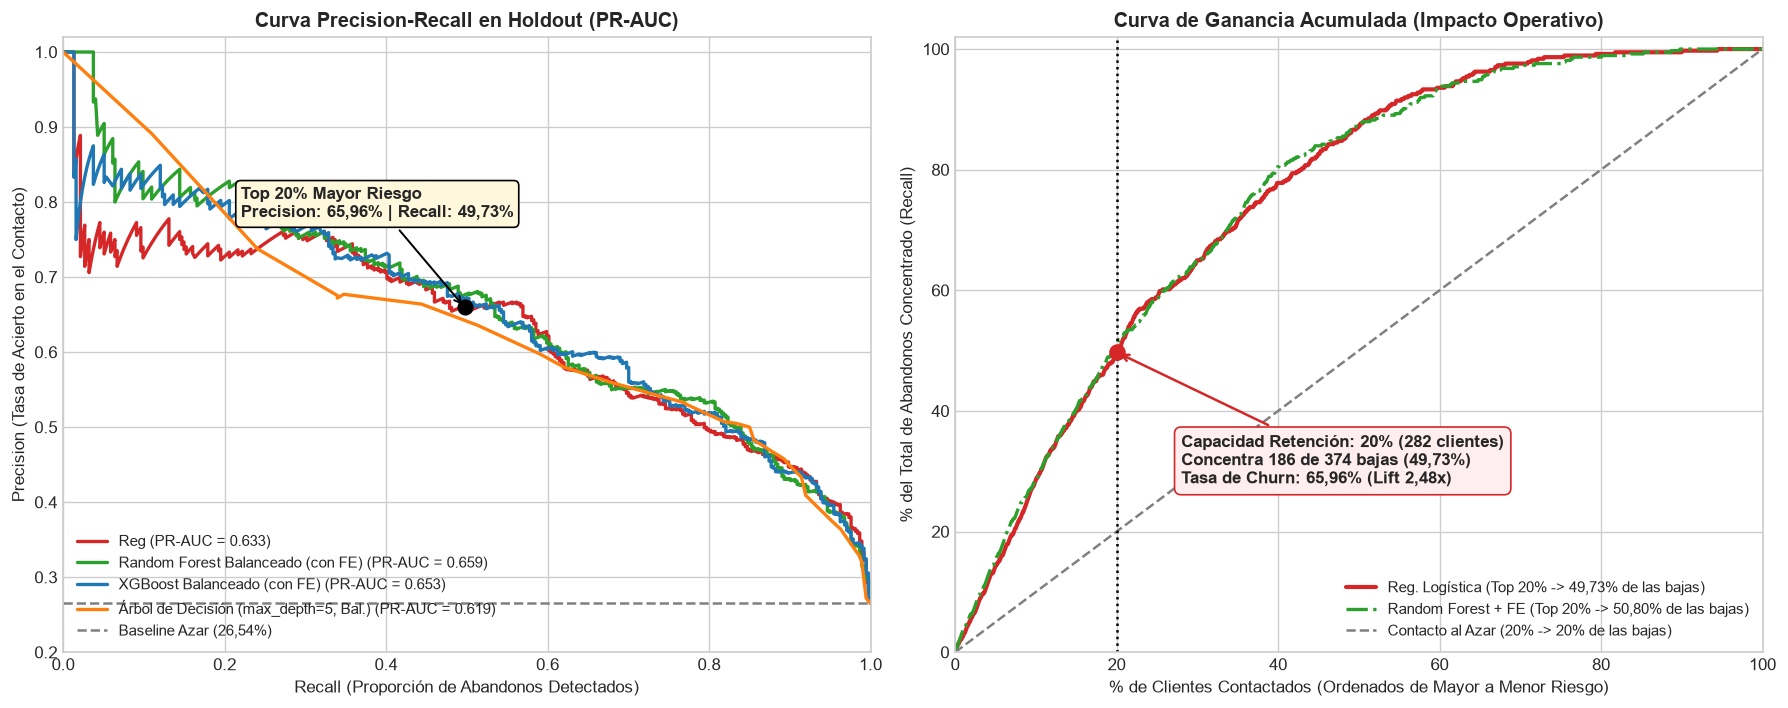

In [7]:
# ==============================================================================
# VISUALIZACIÓN DE EVALUACIÓN: CURVA PRECISION-RECALL Y CURVA DE GANANCIA ACUMULADA
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 6), dpi=120)

# 1. Curva Precision-Recall (Métrica prioritaria ante desbalance de clases)
ax1 = axes[0]
modelos_graf = [
    ('3. Reg. Logística Balanceada (Pre-entrega)', '#d62728'),
    ('5. Random Forest Balanceado (con FE)', '#2ca02c'),
    ('6. XGBoost Balanceado (con FE)', '#1f77b4'),
    ('4. Árbol de Decisión (max_depth=5, Bal.)', '#ff7f0e')
]

for nombre, color in modelos_graf:
    prec, rec, _ = precision_recall_curve(y_test, probs_test[nombre])
    pr_auc = average_precision_score(y_test, probs_test[nombre])
    ax1.plot(rec, prec, label=f"{nombre.split('. ')[1]} (PR-AUC = {pr_auc:.3f})", color=color, linewidth=2)

ax1.axhline(base_rate_test, color='gray', linestyle='--', label='Baseline Azar (26,54%)')
ax1.scatter([0.4973], [0.6596], color='black', zorder=5, s=75)
ax1.annotate('Top 20% Mayor Riesgo\nPrecision: 65,96% | Recall: 49,73%',
             xy=(0.4973, 0.6596), xytext=(0.22, 0.78),
             arrowprops=dict(arrowstyle='->', color='black', lw=1.2),
             fontweight='bold', bbox=dict(boxstyle='round,pad=0.3', fc='#fff8dc', ec='black'))

ax1.set_title('Curva Precision-Recall en Holdout (PR-AUC)', fontweight='bold')
ax1.set_xlabel('Recall (Proporción de Abandonos Detectados)')
ax1.set_ylabel('Precision (Tasa de Acierto en el Contacto)')
ax1.set_xlim([0.0, 1.0])
ax1.set_ylim([0.2, 1.02])
ax1.legend(loc='lower left', fontsize=9)

# 2. Curva de Ganancia Acumulada (% de Cartera Contactada vs % de Abandonos Concentrados)
ax2 = axes[1]
pct_cartera = np.arange(1, len(df_ranking) + 1) / len(df_ranking) * 100
pct_bajas_lr = df_ranking['Churn_Real'].cumsum() / total_churn_test * 100

df_rf = pd.DataFrame({'y': y_test.values, 'p': probs_test['5. Random Forest Balanceado (con FE)']}).sort_values('p', ascending=False)
pct_bajas_rf = df_rf['y'].cumsum() / total_churn_test * 100

ax2.plot(pct_cartera, pct_bajas_lr, label='Reg. Logística (Top 20% -> 49,73% de las bajas)', color='#d62728', linewidth=2.5)
ax2.plot(pct_cartera, pct_bajas_rf, label='Random Forest + FE (Top 20% -> 50,80% de las bajas)', color='#2ca02c', linewidth=2, linestyle='-.')
ax2.plot([0, 100], [0, 100], color='gray', linestyle='--', label='Contacto al Azar (20% -> 20% de las bajas)')

ax2.axvline(20, color='black', linestyle=':', linewidth=1.5)
ax2.scatter([20], [49.7326], color='#d62728', zorder=5, s=80)
ax2.annotate('Capacidad Retención: 20% (282 clientes)\nConcentra 186 de 374 bajas (49,73%)\nTasa de Churn: 65,96% (Lift 2,48x)',
             xy=(20, 49.7326), xytext=(28, 28),
             arrowprops=dict(arrowstyle='->', color='#d62728', lw=1.5),
             fontweight='bold', bbox=dict(boxstyle='round,pad=0.4', fc='#ffeef0', ec='#d62728'))

ax2.set_title('Curva de Ganancia Acumulada (Impacto Operativo)', fontweight='bold')
ax2.set_xlabel('% de Clientes Contactados (Ordenados de Mayor a Menor Riesgo)')
ax2.set_ylabel('% del Total de Abandonos Concentrado (Recall)')
ax2.set_xlim([0, 100])
ax2.set_ylim([0, 102])
ax2.legend(loc='lower right', fontsize=9)

plt.tight_layout()
plt.show()

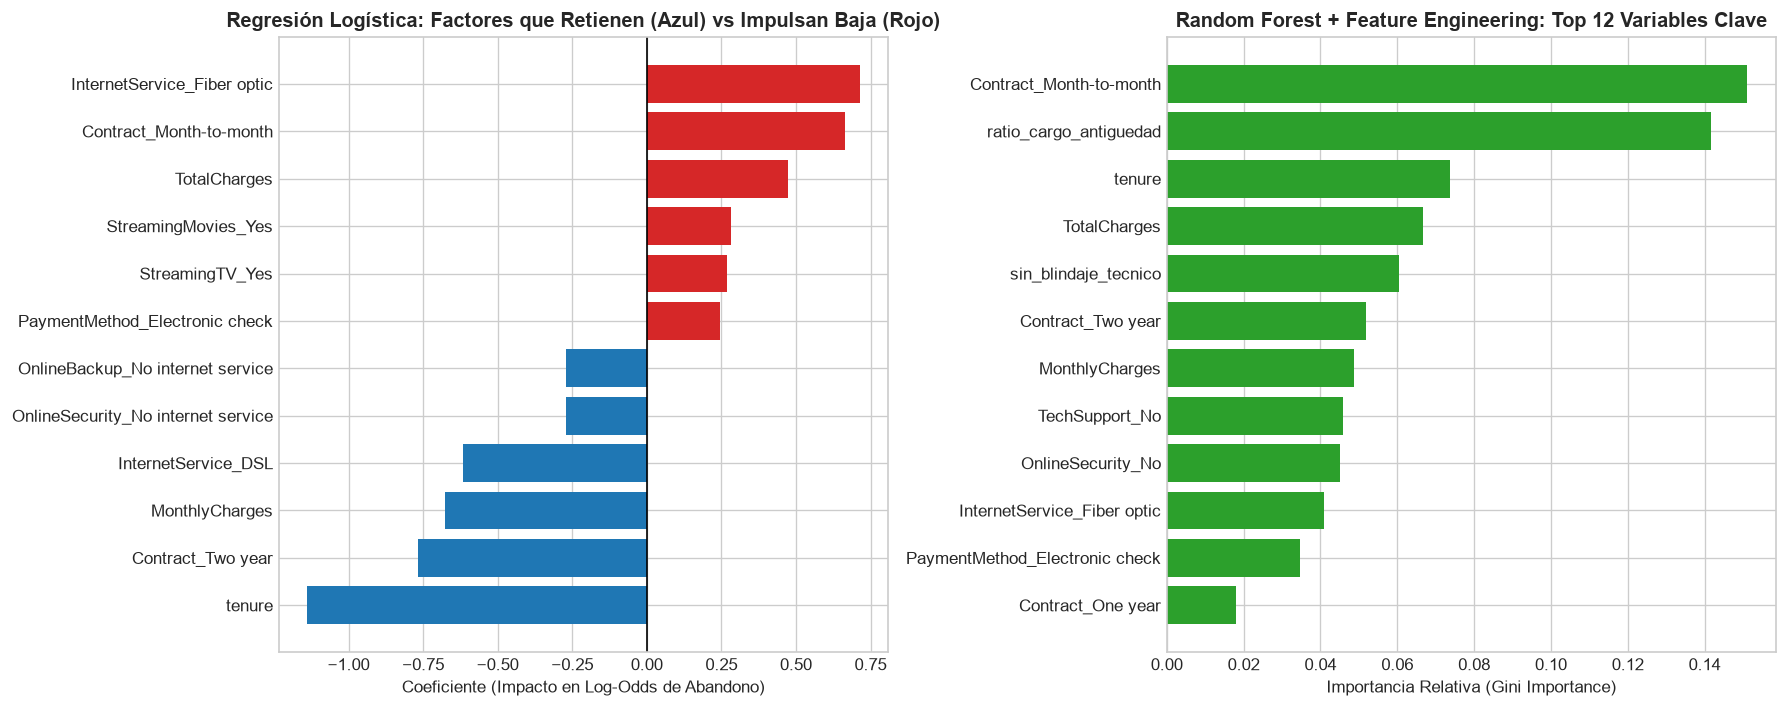

In [8]:
# ==============================================================================
# INTERPRETABILIDAD: FACTORES IMPULSORES DE CHURN Y RANKING DE IMPORTANCIA
# ==============================================================================
pipe_lr = modelos_entrenados['3. Reg. Logística Balanceada (Pre-entrega)']
pipe_rf = modelos_entrenados['5. Random Forest Balanceado (con FE)']

# Extraer nombres de variables y coeficientes / importancias
nombres_lr = [n.replace('cat__', '').replace('num__', '') for n in pipe_lr.named_steps['prep'].get_feature_names_out()]
coefs_lr = pd.Series(pipe_lr.named_steps['clf'].coef_[0], index=nombres_lr).sort_values()

nombres_rf = [n.replace('cat__', '').replace('num__', '') for n in pipe_rf.named_steps['prep'].get_feature_names_out()]
imp_rf = pd.Series(pipe_rf.named_steps['clf'].feature_importances_, index=nombres_rf).sort_values(ascending=False).head(12)

fig, axes = plt.subplots(1, 2, figsize=(15, 6), dpi=120)

# Gráfico 1: Coeficientes de Regresión Logística
top_coefs = pd.concat([coefs_lr.head(6), coefs_lr.tail(6)])
colores_barras = ['#1f77b4' if v < 0 else '#d62728' for v in top_coefs.values]
axes[0].barh(top_coefs.index, top_coefs.values, color=colores_barras)
axes[0].axvline(0, color='black', linewidth=1)
axes[0].set_title('Regresión Logística: Factores que Retienen (Azul) vs Impulsan Baja (Rojo)', fontweight='bold')
axes[0].set_xlabel('Coeficiente (Impacto en Log-Odds de Abandono)')

# Gráfico 2: Top 12 Variables más importantes en Random Forest con Feature Engineering
axes[1].barh(imp_rf.index[::-1], imp_rf.values[::-1], color='#2ca02c')
axes[1].set_title('Random Forest + Feature Engineering: Top 12 Variables Clave', fontweight='bold')
axes[1].set_xlabel('Importancia Relativa (Gini Importance)')

plt.tight_layout()
plt.show()

## Conclusiones, Acciones de Retención y Consideraciones Éticas

### 1. Valor de Negocio e Iniciativas Accionables sobre el Top 20%
* **Eficiencia en la priorización:** El modelo no reduce el churn por sí mismo, sino que transforma la eficiencia de las campañas de Retención. Si el equipo comercial tiene capacidad para contactar al **20% de la cartera (282 clientes en validación)**, pasar de llamadas al azar a la lista priorizada por el modelo permite subir la tasa de acierto del **26,54% al 65,96% (Lift = 2,48x)** y **concentrar el 49,73% de todos los abandonos reales de la compañía (186 de 374 bajas)** en apenas una quinta parte de la base.
* **Acciones recomendadas por perfil de riesgo detectado:**
  1. **Migración contractual incentivada:** Para clientes en el Top 20% con contrato `Month-to-month` y alta presión tarifaria inicial (`ratio_cargo_antiguedad`), ofrecer bonificación parcial sujeta a migración a contrato anual (`One year`).
  2. **Blindaje técnico gratuito por 6 meses:** Para usuarios de `Fiber optic` identificados con `sin_blindaje_tecnico = 1`, incluir pruebas bonificadas de `OnlineSecurity` y `TechSupport` para aumentar los costos de cambio (*switching costs*) y reducir la tasa de baja.
  3. **Fidelización de medios de pago:** Incentivar el paso de `Electronic check` (45,29% de churn) hacia débito automático bancario o tarjeta de crédito (~15-16% de churn).

### 2. Consideraciones Éticas, Sesgos y Privacidad de Datos
* **Protección de Datos Personales:** Se excluyó el identificador `customerID` del entrenamiento y en un despliegue productivo en Argentina el tratamiento debe regirse por la **Ley N.º 25.326 de Protección de los Datos Personales**, garantizando anonimización y consentimiento para comunicaciones comerciales.
* **Mitigación de sesgos demográficos:** Las variables demográficas sensibles como `gender` o `SeniorCitizen` tienen peso marginal frente a las variables de relación contractual y servicio (`Contract`, `tenure`, `InternetService`). Se recomienda auditar periódicamente las campañas para evitar discriminación tarifaria por edad o género.